BÀI 5: GOM CỤM KHỐI U LÀNH TÍNH VÀ ÁC TÍNH (BREAST CANCER)
Sinh viên: Vũ Trương Phi - MSSV: 6451071059

Số lượng mẫu: 569, Số đặc trưng: 30
Tỉ lệ nhãn thực tế: Malignant = 212, Benign = 357

Độ chính xác gom cụm (Clustering Accuracy): 90.51%

Báo cáo chi tiết (Classification Report):
              precision    recall  f1-score   support

   malignant       0.91      0.83      0.87       212
      benign       0.90      0.95      0.93       357

    accuracy                           0.91       569
   macro avg       0.91      0.89      0.90       569
weighted avg       0.91      0.91      0.90       569



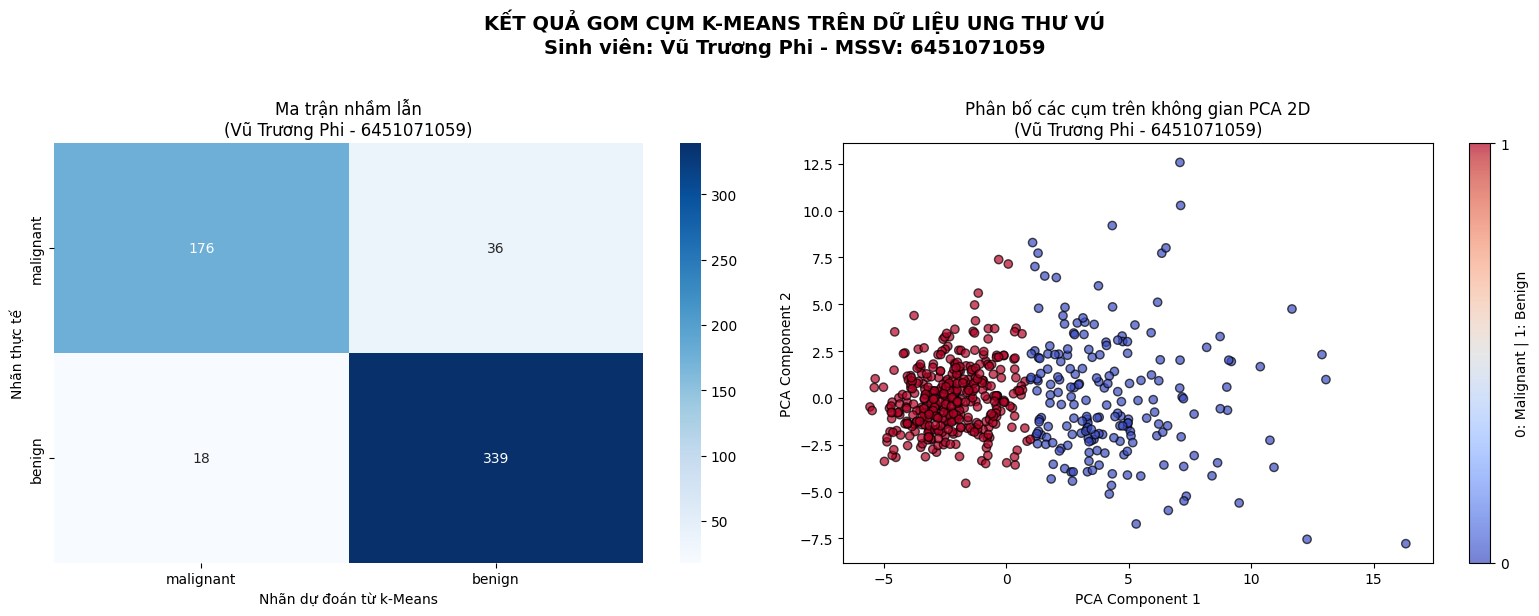

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import mode
from sklearn.cluster import KMeans
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.preprocessing import StandardScaler

# Thông tin sinh viên
ten = "Vũ Trương Phi"
mssv = "6451071059"
print("=" * 65)
print(f"BÀI 5: GOM CỤM KHỐI U LÀNH TÍNH VÀ ÁC TÍNH (BREAST CANCER)")
print(f"Sinh viên: {ten} - MSSV: {mssv}")
print("=" * 65)

# 1. Tải bộ dữ liệu ung thư vú Wisconsin
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target  # 0: Malignant (Ác tính), 1: Benign (Lành tính)
target_names = cancer.target_names  # ['malignant', 'benign']

print(f"\nSố lượng mẫu: {X.shape[0]}, Số đặc trưng: {X.shape[1]}")
print(f"Tỉ lệ nhãn thực tế: Malignant = {np.sum(y == 0)}, Benign = {np.sum(y == 1)}")

# 2. Chuẩn hóa đặc trưng (StandardScaler) để k-Means tính khoảng cách chuẩn xác
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Áp dụng k-Means với k = 2 (Lành tính và Ác tính)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# 4. Ánh xạ nhãn cụm (cluster) về nhãn thực tế (ground truth)
labels = np.zeros_like(clusters)
for i in range(2):
  mask = clusters == i
  labels[mask] = mode(y[mask], keepdims=True)[0]

# 5. Đánh giá kết quả gom cụm
acc = accuracy_score(y, labels)
print(f"\nĐộ chính xác gom cụm (Clustering Accuracy): {acc * 100:.2f}%\n")
print("Báo cáo chi tiết (Classification Report):")
print(classification_report(y, labels, target_names=target_names))

# 6. Trực quan hóa kết quả: Ma trận nhầm lẫn & Không gian 2D (PCA)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Đồ thị 1: Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y, labels)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
    ax=ax[0],
)
ax[0].set_xlabel("Nhãn dự đoán từ k-Means")
ax[0].set_ylabel("Nhãn thực tế")
ax[0].set_title(f"Ma trận nhầm lẫn\n({ten} - {mssv})")

# Đồ thị 2: Chiếu dữ liệu xuống 2 chiều PCA để quan sát cụm
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

scatter = ax[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="coolwarm",
    alpha=0.7,
    edgecolors="k",
)
ax[1].set_xlabel("PCA Component 1")
ax[1].set_ylabel("PCA Component 2")
ax[1].set_title(f"Phân bố các cụm trên không gian PCA 2D\n({ten} - {mssv})")
plt.colorbar(scatter, ax=ax[1], ticks=[0, 1], label="0: Malignant | 1: Benign")

plt.suptitle(
    f"KẾT QUẢ GOM CỤM K-MEANS TRÊN DỮ LIỆU UNG THƯ VÚ\nSinh viên: {ten} - MSSV: {mssv}",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()